# The rate model

Two memory pools (cued, uncued) with slow recurrent excitation and shared inhibition, driven by a common input that dips (`nmdaint/ratemodel.py`). Parameters are the fitted ones (`ratemodel.FIT`); change any of them with `ratemodel.params(model, name=value)`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, matplotlib.pyplot as plt
from nmdaint import ratemodel, readout, onoff
ratemodel.params('nmda')

{'model': 'nmda',
 'r_max': 150.0,
 'kappa': 0.06,
 'w_a': 0.0141,
 'beta': 0.02,
 'w_I': 0.04,
 'w_EI': 0.5,
 'w_ff': 0.8,
 'tau_ff': 15.0,
 'I_0': 1.496,
 'tau_r': 10.0,
 'tau_I': 1.0,
 'tau_xi': 10.0,
 'cue_amp': 1.0,
 'cue_dur': 50.0,
 't_pre': 300.0,
 't_delay': 1600.0,
 'dt': 0.1,
 'U': 0.3,
 'tau_d': 300.0,
 'tau_N': 150.0,
 'w_s': 1.3,
 'dip_rate': 10.207,
 'dip_mean': 90.12,
 'dip_shape': 8.7,
 'dip_depth': 0.5987,
 'sigma': 0.0058}

## One trial
Dips silence both pools; when the input returns, the pool that kept more NMDA gating wins.

memory held at the end of the delay: [ True  True  True  True  True]


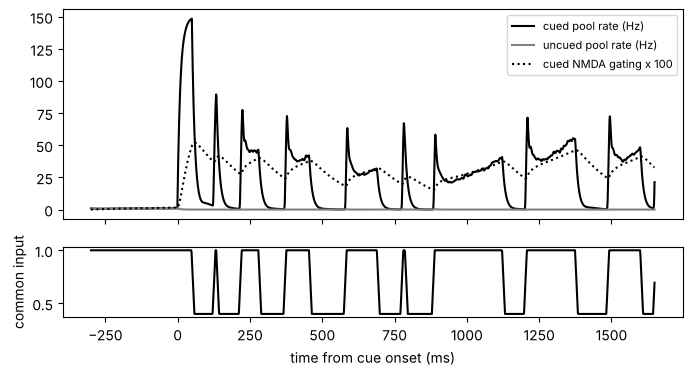

In [2]:
p = ratemodel.params('nmda')
sim = ratemodel.simulate(p, n_tr=5, seed=1)
k = 0
fig, ax = plt.subplots(2, 1, figsize=(8, 4), sharex=True, height_ratios=(3, 1))
ax[0].plot(sim['t'], sim['rc'][k], 'k', label='cued pool rate (Hz)')
ax[0].plot(sim['t'], sim['ru'][k], 'grey', label='uncued pool rate (Hz)')
ax[0].plot(sim['t'], 100 * sim['sc'][k], 'k:', label='cued NMDA gating x 100')
ax[1].plot(sim['t'], sim['m'][k], 'k'); ax[1].set_ylabel('common input')
ax[0].legend(fontsize=8); ax[1].set_xlabel('time from cue onset (ms)')
print('memory held at the end of the delay:', ratemodel.memory_correct(sim))

## Read out like the data
`z = c dr + eta`: the rate difference in 100 ms windows times a gain, plus noise (`nmdaint/readout.py`); On/Off labels as for the recordings (`nmdaint/onoff.py`). The gain is the one calibrated to the all-units decoder in the paper.

3.04 Off and 1.77 On states per trial; delay 0.40 Off, 0.18 On


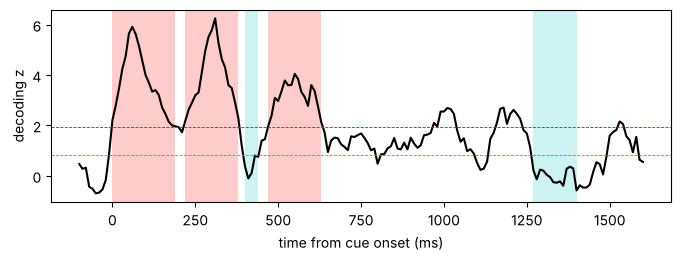

In [3]:
ses, _ = readout.load_data()                    # the data's decoding strength sets the gain
gain = readout.evaluate(p, ses, n_trials=2112, seed=1)['sets']['all']['gain']
sim = ratemodel.simulate(p, n_tr=200, seed=2)
dw, tz = readout.rate_diff(sim)
rng = np.random.default_rng(0)
z = gain * dw + readout.noise(dw.shape, readout.RHO['all'], rng)
state = onoff.label(z, readout.null_threshold(dw.shape, readout.RHO['all'], rng), (tz >= 0) & (tz <= 1400))
k = 0
plt.figure(figsize=(8, 2.5))
plt.plot(tz, z[k], 'k')
for v, c in ((1, 'r'), (-1, 'c')):
    for a, b in onoff.runs(state[k] == v):
        plt.axvspan(tz[a], tz[b - 1], color=c, alpha=0.2, lw=0)
plt.axhline(1.96, color='r', ls='--', lw=0.6); plt.axhline(0.84, color='c', ls='--', lw=0.6)
plt.xlabel('time from cue onset (ms)'); plt.ylabel('decoding z')
s = onoff.stats(state, (tz >= 500) & (tz <= 1400))
print(f"{s['n_off']:.2f} Off and {s['n_on']:.2f} On states per trial; delay {s['frac_off']:.2f} Off, {s['frac_on']:.2f} On")

## One silence: NMDA vs STP (Fig. 3a)
One dip of fixed length, no other dips. The NMDA trace decays with tau_N, so long silences erase the memory; facilitation (tau_f = 1.5 s) bridges them.

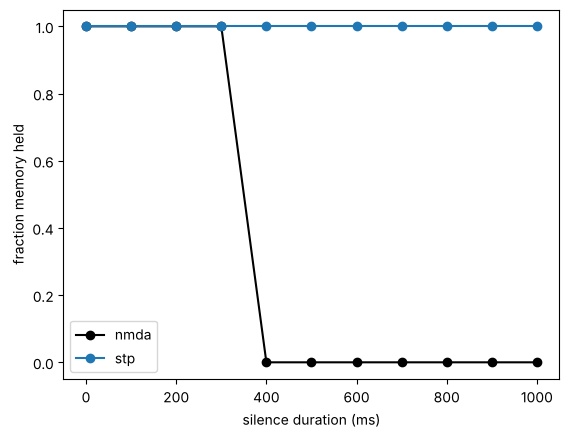

In [4]:
lengths = np.arange(0, 1001, 100)
for model, col in (('nmda', 'k'), ('stp', 'tab:blue')):
    p = ratemodel.params(model)
    held = [ratemodel.memory_correct(ratemodel.simulate(p, 50, seed=i, m=ratemodel.single_dip(p, 50, 500, L))).mean()
            for i, L in enumerate(lengths)]
    plt.plot(lengths, held, 'o-', color=col, label=model)
plt.xlabel('silence duration (ms)'); plt.ylabel('fraction memory held'); plt.legend()

## Try it
Shorter NMDA time constant: the same dips now erase the memory more often.

In [5]:
for tau in (60, 100, 150):
    sim = ratemodel.simulate(ratemodel.params('nmda', tau_N=tau), 200, seed=3)
    print(f'tau_N {tau} ms: memory held in {ratemodel.memory_correct(sim).mean():.2f} of trials')

tau_N 60 ms: memory held in 0.67 of trials


tau_N 100 ms: memory held in 0.92 of trials


tau_N 150 ms: memory held in 0.99 of trials
